## Apresentação

Este notebook foi criado para mostrar como você pode realizar um controle de qualidade em perfis de poços utilizando gráficos úteis das bibliotecas matplotlib e seaborn, além de funções de análise descritiva do pandas. Isso, combinado com processos de interpretação, otimiza a percepção dos dados e ajuda a gerar insights valiosos

## Descrição do Dado

Este conjunto de dados é oriundo de uma competição de machine learning para classificação de fácies de diversos poços (https://github.com/seg/2016-ml-contest). São poços do campo Panoma Council Grove, no sudoeste do Kansas - EUA, onde existem predominantemente reservatórios de gás em rochas carbonáticas, abrangendo uma área de 2.700 milhas quadradas no sudoeste do Kansas. Este conjunto de dados provém de nove poços (com 4.149 amostras), consistindo em um conjunto de sete variáveis preditoras e uma variável de fácies (classe). As fácies são baseadas na análise de testemunhos de sondagem retirados verticalmente em intervalos de meio pé nos nove poços.

As nove classes de rochas são: 

1. Nonmarine sandstone
2. Nonmarine coarse siltstone
3. Nonmarine fine siltstone
4. Marine siltstone and shale
5. Mudstone (limestone)
6. Wackestone (limestone)
7. Dolomite
8. Packstone-grainstone (limestone)
9. Phylloid-algal bafflestone (limestone)

As variáveis preditoras incluem cinco medidas obtidas por perfis de poço (wireline logs) e duas variáveis geológicas de restrição, derivadas do conhecimento geológico. Estas são essencialmente variáveis contínuas, amostradas a cada meio pé de profundidade.

Os logs disponíveis:
GR (gamma ray), ILD_log10 (resistividade), PE (efeito fotoelétrico), DeltaPHI (diferença entre porosidades neutrão-densidade), PHIND (porosidade média entre neutrão-densidade). E duas variáveis de restrição geológica: NM_M (indicador não marinho ou marinho) e RELPOS (posição relativa).

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Caminho da pasta principal
rootdir = "C:/Users/lucas.aguiar/Desktop/Pastas/B2S/4_analise_exploratoria_logs/"

In [3]:
# Importação do dado
data = pd.read_csv(rootdir + "training_data.csv", sep=",")

In [4]:
# Visualização simplificada do dado
print("Data Size (rows, cols):", data.shape)

data.head(10)

Data Size (rows, cols): (3232, 11)


,Facies,Formation,Well Name,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
0,3,A1 SH,SHRIMPLIN,2793.0,77.45,0.664,9.9,11.915,4.6,1,1.000
1,3,A1 SH,SHRIMPLIN,2793.5,78.26,0.661,14.2,12.565,4.1,1,0.979
2,3,A1 SH,SHRIMPLIN,2794.0,79.05,0.658,14.8,13.050,3.6,1,0.957
3,3,A1 SH,SHRIMPLIN,2794.5,86.10,0.655,13.9,13.115,3.5,1,0.936
4,3,A1 SH,SHRIMPLIN,2795.0,74.58,0.647,13.5,13.300,3.4,1,0.915
5,3,A1 SH,SHRIMPLIN,2795.5,73.97,0.636,14.0,13.385,3.6,1,0.894
6,3,A1 SH,SHRIMPLIN,2796.0,73.72,0.630,15.6,13.930,3.7,1,0.872
7,3,A1 SH,SHRIMPLIN,2796.5,75.65,0.625,16.5,13.920,3.5,1,0.830
8,3,A1 SH,SHRIMPLIN,2797.0,73.79,0.624,16.2,13.980,3.4,1,0.809
9,3,A1 SH,SHRIMPLIN,2797.5,76.89,0.615,16.9,14.220,3.5,1,0.787


In [5]:
# Busca por valores ausentes
data.isna().sum()

Facies       0
Formation    0
Well Name    0
Depth        0
GR           0
ILD_log10    0
DeltaPHI     0
PHIND        0
PE           0
NM_M         0
RELPOS       0
dtype: int64

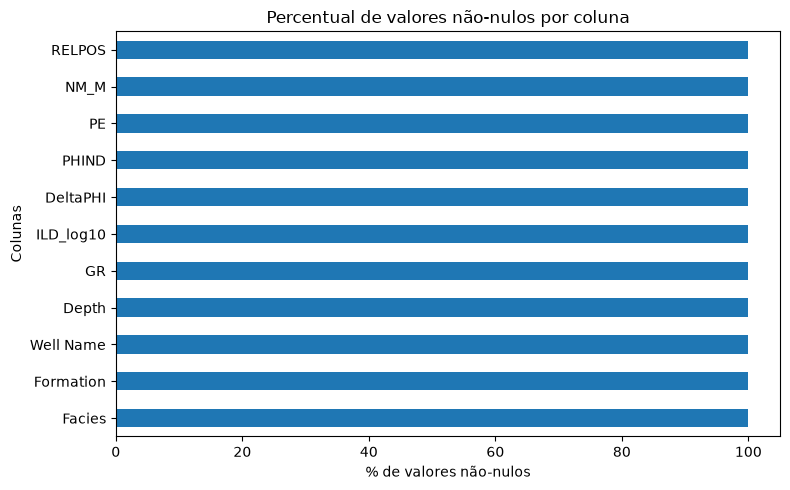

In [6]:
# Visualização da porcentagem de valores presentes/ausentes
(data.notnull().mean() * 100).sort_values().plot(kind='barh', figsize=(8, 5))

plt.xlabel('% de valores não-nulos')
plt.ylabel('Colunas')
plt.title('Percentual de valores não-nulos por coluna')
plt.tight_layout()
plt.show()

### Observação

A estatística descritiva ajuda a entender rapidamente a distribuição de cada coluna numérica do seu dado. Ela indica a contagem de valores não-nulos, média, desvio padrão, mínimo, máximo e quartis. 

Com base nessas indicações já é possível entender se o seu dado apresenta valores irreais e de referência. Por exemplo, o valor máximo de PHIND está como 84.40, mas medidas de porosidade geralmente estão entre 0 e 40 para rochas consolidadas. Esse seria um ponto de atenção para investigar a que rocha está associada e se precisamos desconsiderar esse valor.

In [7]:
# Estatística descritiva
data.describe()

,Facies,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
count,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000,3232.000000
mean,4.422030,2875.824567,66.135769,0.642719,3.559642,13.483213,3.725014,1.498453,0.520287
std,2.504243,131.006274,30.854826,0.241845,5.228948,7.698980,0.896152,0.500075,0.286792
min,1.000000,2573.500000,13.250000,-0.025949,-21.832000,0.550000,0.200000,1.000000,0.010000
25%,2.000000,2791.000000,46.918750,0.492750,1.163750,8.346750,3.100000,1.000000,0.273000
50%,4.000000,2893.500000,65.721500,0.624437,3.500000,12.150000,3.551500,1.000000,0.526000
75%,6.000000,2980.000000,79.626250,0.812735,6.432500,16.453750,4.300000,2.000000,0.767250
max,9.000000,3122.500000,361.150000,1.480000,18.600000,84.400000,8.094000,2.000000,1.000000


In [8]:
# Verificação de fácies com porosidades muito altas
high_phind = data.loc[data["PHIND"] > 50]
high_phind.head(10)

,Facies,Formation,Well Name,Depth,GR,ILD_log10,DeltaPHI,PHIND,PE,NM_M,RELPOS
759,3,B4 SH,SHANKLE,2922.5,74.510,0.538000,-7.400,51.805,2.000,1,0.042
850,3,C SH,SHANKLE,2972.5,76.720,0.603000,-9.900,51.300,1.800,1,0.070
851,3,C SH,SHANKLE,2973.0,75.010,0.654000,-18.300,55.915,1.800,1,0.053
1497,3,B1 SH,CROSS H CATTLE,2632.5,122.568,0.578754,-16.400,71.700,0.990,1,0.955
1498,2,B1 SH,CROSS H CATTLE,2633.0,120.345,0.568319,2.000,84.400,0.833,1,0.939
1499,2,B1 SH,CROSS H CATTLE,2633.5,109.836,0.562055,1.500,81.650,0.852,1,0.924
1500,2,B1 SH,CROSS H CATTLE,2634.0,94.623,0.566437,-10.300,65.850,1.234,1,0.909
1501,2,B1 SH,CROSS H CATTLE,2634.5,85.419,0.593397,-14.500,50.850,1.787,1,0.894
1793,3,C SH,CROSS H CATTLE,2788.0,75.107,0.480725,-16.000,75.500,0.646,1,0.645
3001,3,B2 SH,CHURCHMAN BIBLE,3004.0,74.500,0.535000,-8.228,52.369,1.513,1,0.583


### Observação
As fácies 2 e 3 representam "Nonmarine coarse siltstone" e "Nonmarine fine siltstone", respectivamente, e esse tipo de rocha costuma apresentar valores relativamente baixos de porosidade. Logo, é possível que essas leituras de PHIND estejam erradas.

In [9]:
# Contagem do número de fácies
data["Facies"].value_counts()

Facies
2    738
3    615
8    498
6    462
1    259
5    217
4    184
9    161
7     98
Name: count, dtype: int64

### Boxplots

São gráficos que resumem a distribuição de uma variável por meio da mediana, quartis e valores extremos, facilitando a identificação de possíveis outliers e entendimento dos ranges de valores mais representativos. Em perfis de poços, podem ser utilizados para comparar a distribuição de diversos perfis entre diferentes fácies ou poços.

In [10]:
# Definição da cor das fácies para plots futuros
facies_colors = {1:'red', 2:'blue', 3:'green', 4:'orange', 5:'purple', 6:'brown', 7:'pink', 8:'gray', 9:'cyan'}

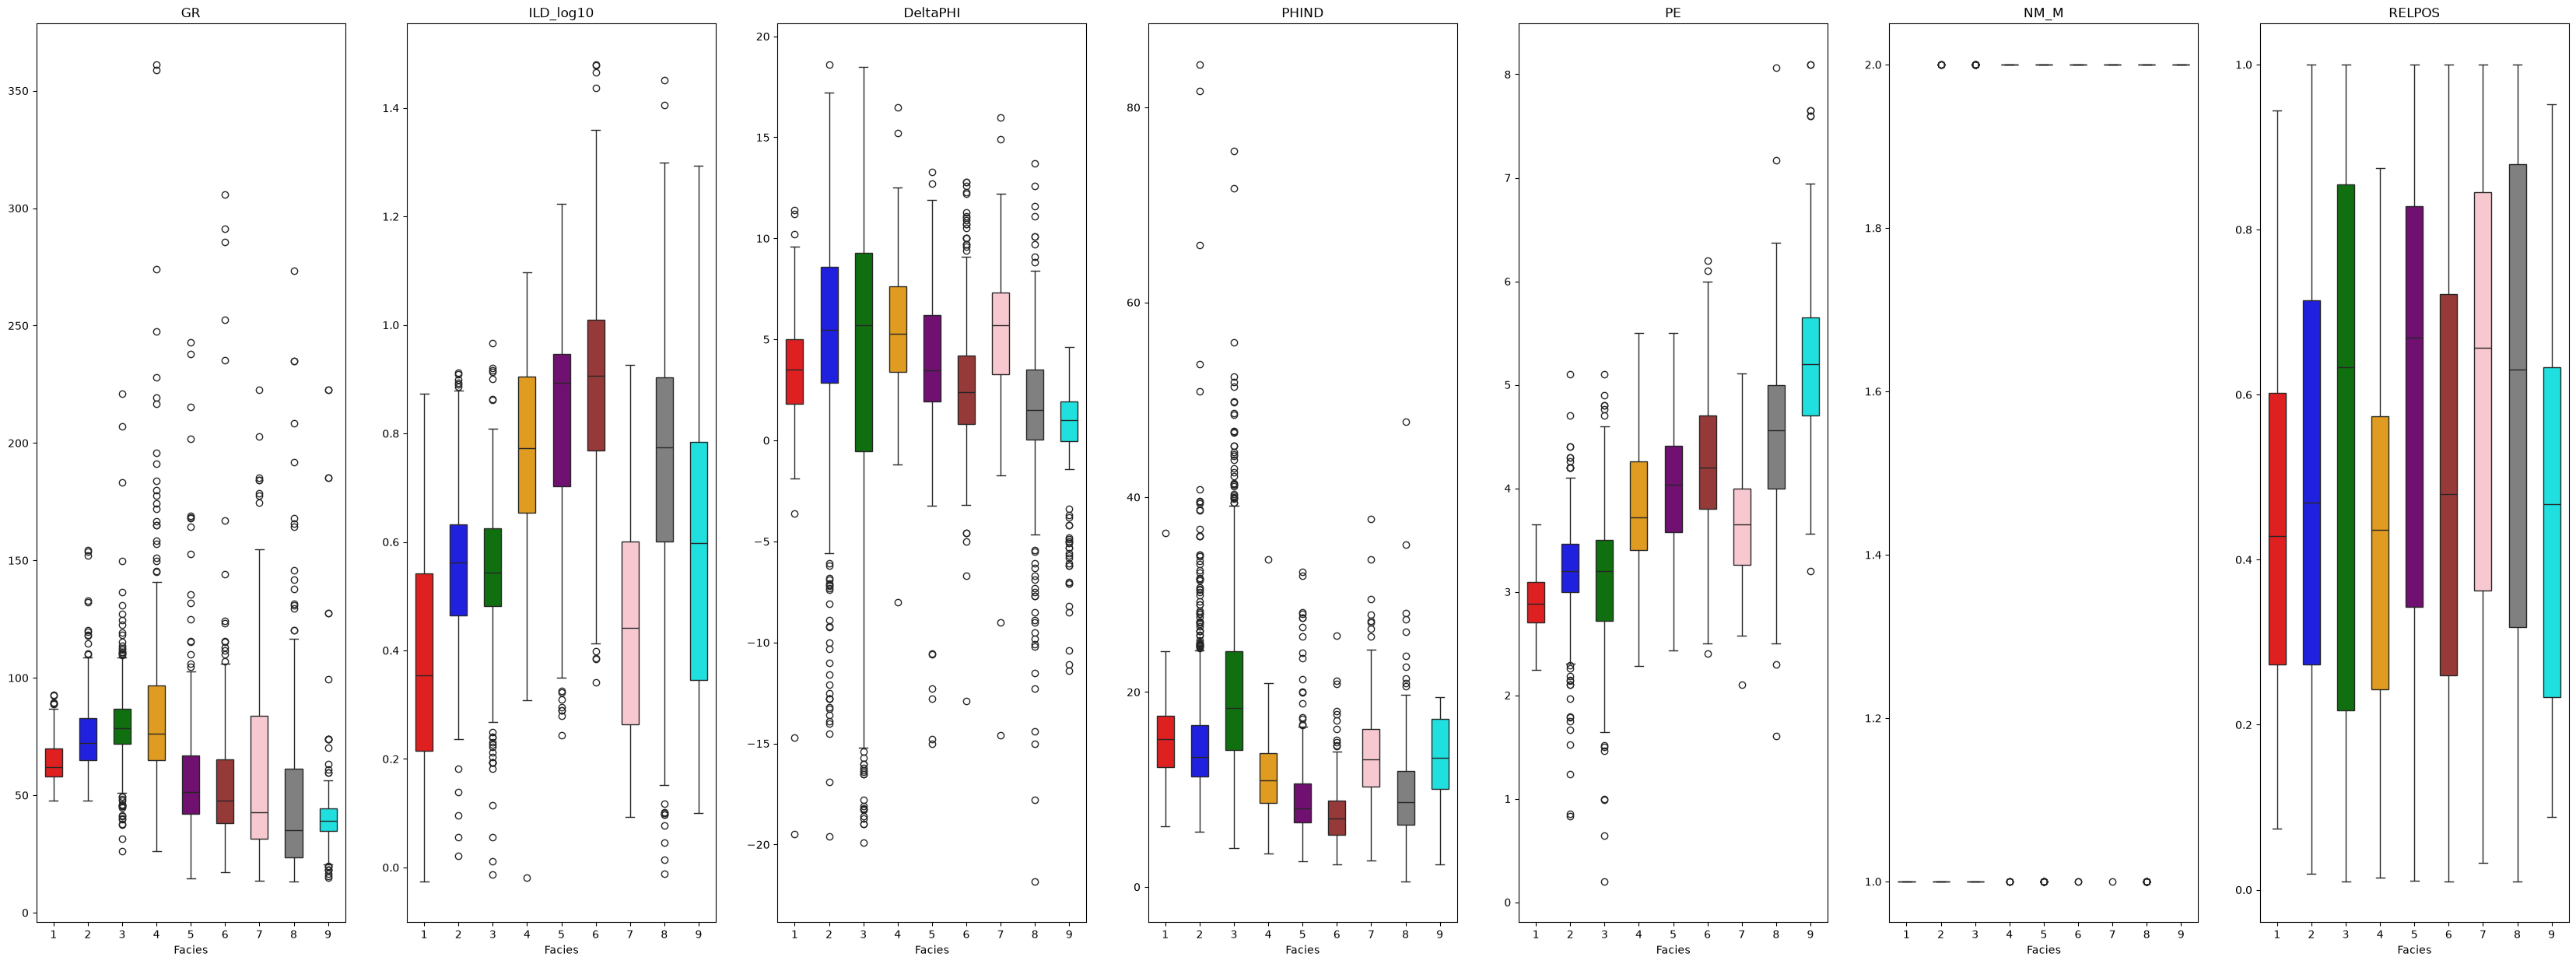

In [11]:
# Boxplot para mostrar a distribuição dos perfis para cada fácies
columns_to_plot = data.drop(["Facies", "Depth", "Formation", "Well Name"], axis=1).columns
num_plots = len(columns_to_plot)

fig, axes = plt.subplots(nrows=1, ncols=num_plots, figsize=(6 * num_plots, 15), sharey=False)

# Plot de cada perfil
# Converter para array unidimensional
axes = axes.flatten()

# Plot de cada perfil
for i, col in enumerate(columns_to_plot):

    sns.boxplot(x="Facies",
                y=col,
                data=data,
                ax=axes[i],
                width=0.5,
                hue="Facies",
                palette=facies_colors,
                legend=False,
                order=sorted(data["Facies"].unique()),
                hue_order=sorted(data["Facies"].unique()))

    axes[i].set_title(col)
    axes[i].set_xlabel("Facies")
    axes[i].set_ylabel("")

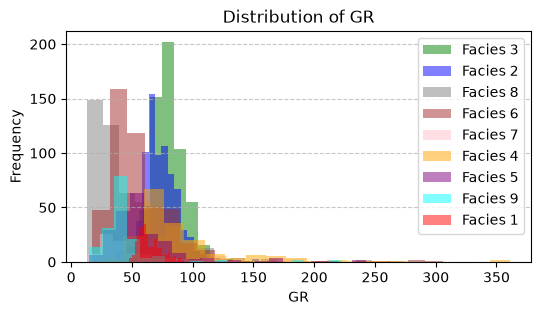

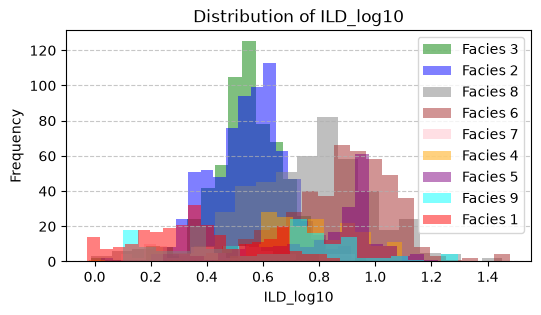

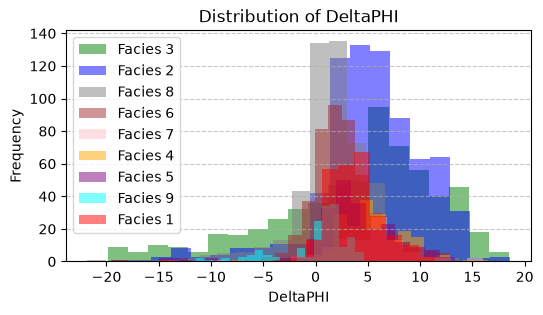

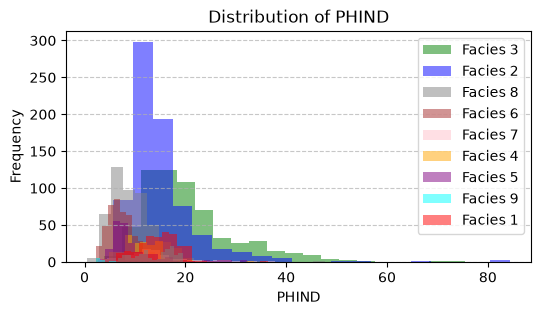

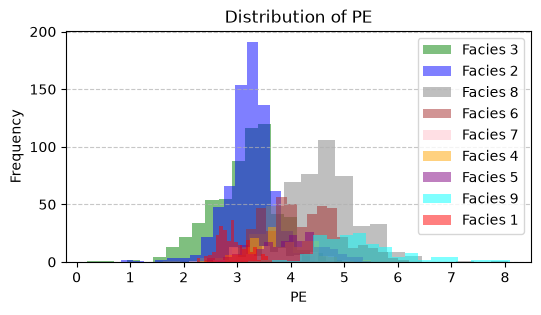

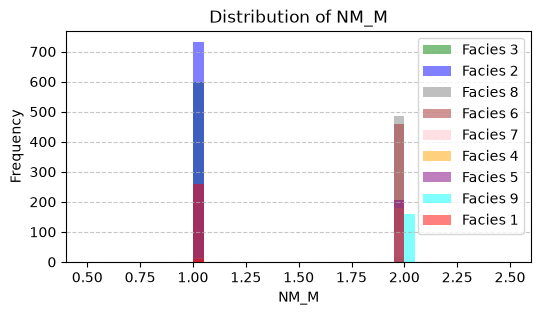

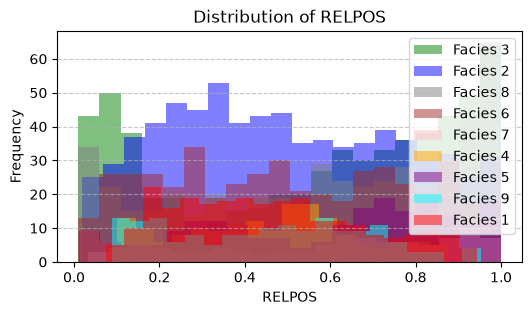

In [12]:
# Histogramas para cada perfil e fácies separadamente
for col in columns_to_plot:
    plt.figure(figsize=(6, 3))
    for facies in data['Facies'].unique():
        subset = data[data['Facies'] == facies]
        plt.hist(subset[col], bins=20, alpha=0.5, label=f'Facies {facies}', color=facies_colors[facies])
    
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

### Pairplots
São gráficos que combinam histogramas e gráficos de dispersão para visualizar a distribuição individual das variáveis e as relações entre pares de variáveis. Em dados de poços, ajudam a identificar correlações, agrupamentos e padrões entre perfis, além de possíveis valores anômalos e tendências associados às fácies.

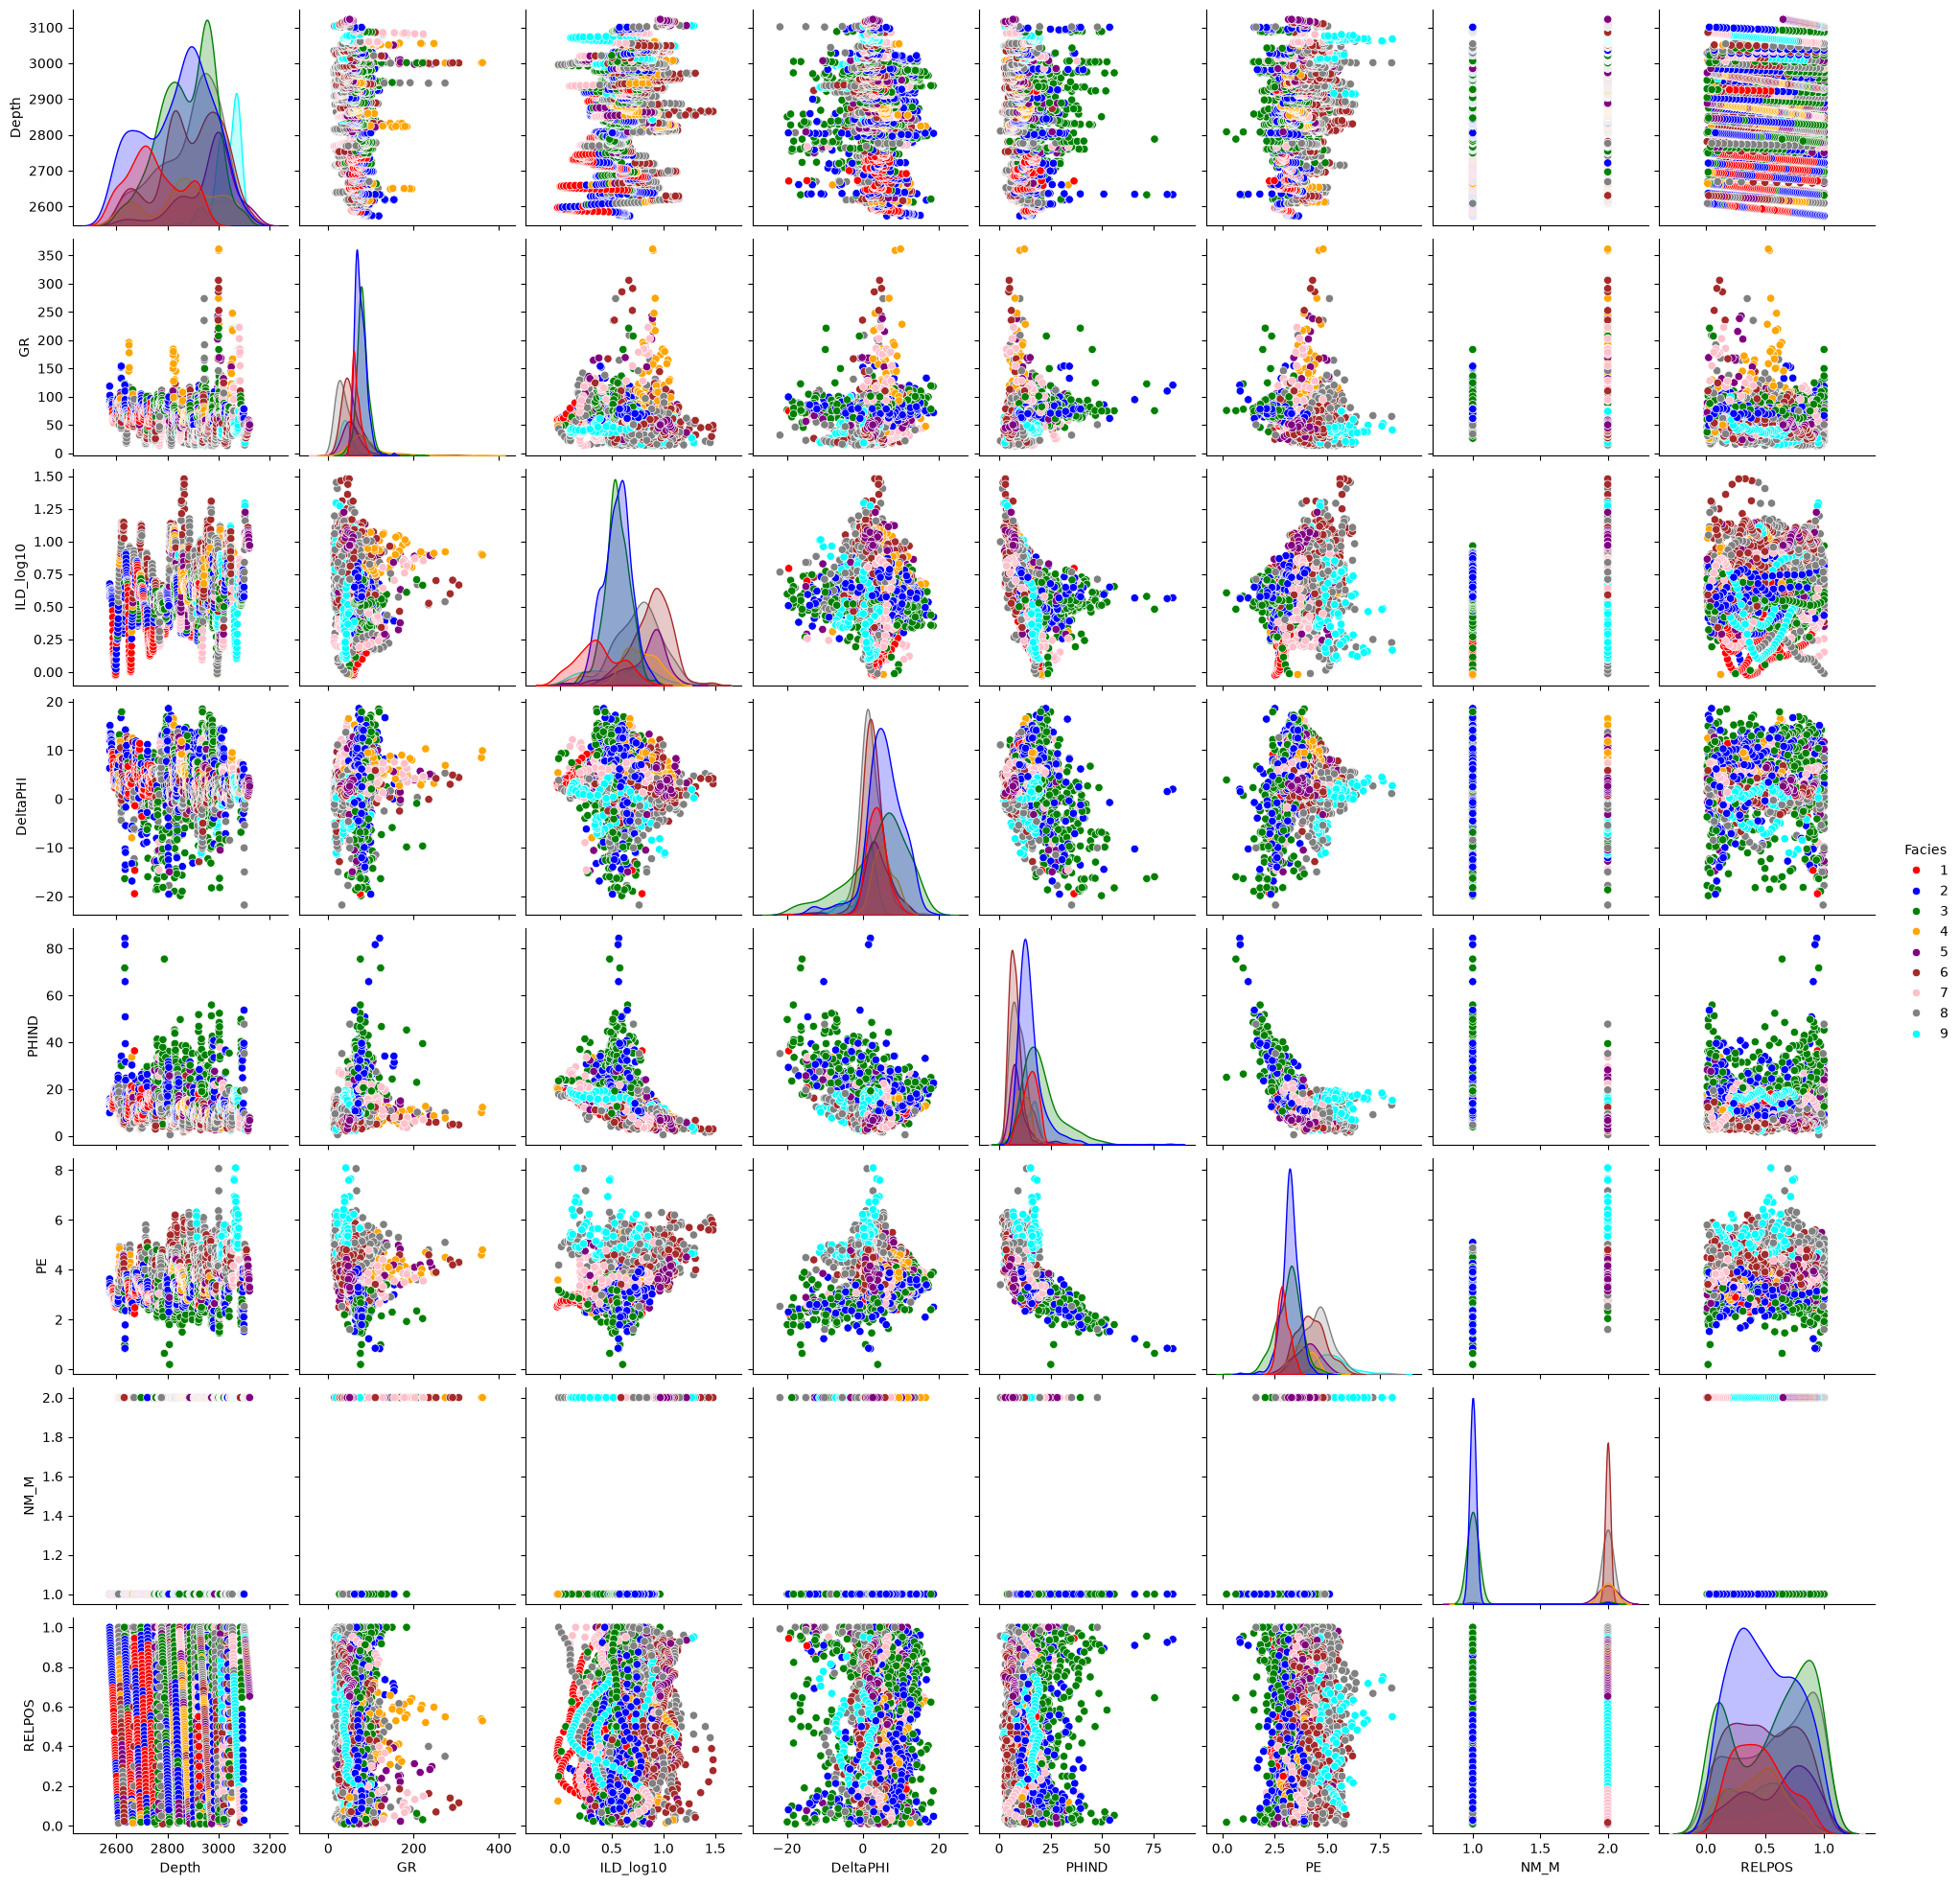

In [13]:
# Pairplot para visualizar tendências
sns.pairplot(data, hue="Facies", palette=facies_colors)